# 01 · The World's Forests

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/oechenique/remote_sensing/blob/main/notebooks/01_world_forests.ipynb)

A global map of **percent tree cover** at 30 arc-seconds (~1 km), plus the numbers behind it: how much land has trees, and how tree cover changes with latitude.

**Data:** Global Map – *Vegetation (Percent Tree Cover) - Global version - Version 1* ([globalmaps/gm_ve_v1](https://github.com/globalmaps/gm_ve_v1), [product page](https://globalmaps.github.io/ptc.html)). Each pixel is the share of the ground covered by tree canopy (0–100 %); `254` marks water.

> Vegetation (Percent Tree Cover) - Global version - Version 1 © Geospatial Information Authority of Japan, Chiba University and Collaborating Organizations

The 80 MB zip is downloaded once and verified by SHA-256 with [`pooch`](https://www.fatiando.org/pooch/); nothing heavy lives in the repo.

## Setup

In [1]:
# Colab already ships numpy and matplotlib; install only what is missing.
# Locally, use requirements.txt instead.
import sys

if "google.colab" in sys.modules:
    %pip install -q rasterio==1.5.2 pooch==1.9.0

In [2]:
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pooch
import rasterio

# Works from notebooks/ in a clone and from a bare Colab session
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data"
IMG_DIR = ROOT / "docs" / "img"
IMG_DIR.mkdir(parents=True, exist_ok=True)

## Download and read

In [3]:
zip_path = pooch.retrieve(
    url="https://github.com/globalmaps/gm_ve_v1/raw/master/gm_ve_v1.zip",
    known_hash="sha256:bf57316c99b6c5cefe5006641ecab97a5df57dcf2ef292e264d15aaefc57f6c9",
    fname="gm_ve_v1.zip",
    path=DATA_DIR,
)

# GDAL reads the GeoTIFF straight out of the zip, no extraction step
with rasterio.open(f"/vsizip/{zip_path}/gm_ve_v1.tif") as src:
    ptc = src.read(1)
    print(f"{src.width} x {src.height} px · {src.crs} · {abs(src.res[0]) * 3600:.0f} arc-seconds per pixel · {ptc.nbytes / 1e6:.0f} MB in memory")

43200 x 21600 px · EPSG:4326 · 30 arc-seconds per pixel · 933 MB in memory


In [4]:
WATER = 254

counts = np.bincount(ptc.ravel(), minlength=256)
present = np.flatnonzero(counts)
print("values present:", present.min(), "to", present[present != WATER].max(), "plus the water flag", WATER)
print(f"water pixels: {counts[WATER] / counts.sum():.1%}")

values present: 0 to 100 plus the water flag 254
water pixels: 67.3%


## Area-weighted statistics

In a lat/lon grid a pixel near the poles covers far less ground than one at the equator, so counting pixels overstates boreal forests. Every row gets its true area on the sphere: $R^2 \, \Delta\lambda \, (\sin\varphi_{top} - \sin\varphi_{bottom})$.

The raster is processed in strips of rows to keep memory flat; the same pass builds a 10× coarser grid for the map.

In [5]:
R_EARTH_KM = 6371.0072  # authalic radius: a sphere with the same surface as the WGS84 ellipsoid
nrows, ncols = ptc.shape
lat_edges = np.linspace(90, -90, nrows + 1)
row_area_km2 = R_EARTH_KM**2 * np.deg2rad(360 / ncols) * (
    np.sin(np.deg2rad(lat_edges[:-1])) - np.sin(np.deg2rad(lat_edges[1:]))
)

FOREST_MIN_COVER = 10  # FAO's forest definition uses a 10 % canopy threshold
F = 10  # 10 x 10 pixels per map cell, ~9 km at the equator
STRIP = 1200

land_px = np.zeros(nrows)
cover_sum = np.zeros(nrows)
forest_px = np.zeros(nrows)
coarse = np.full((nrows // F, ncols // F), np.nan, dtype=np.float32)

for r in range(0, nrows, STRIP):
    strip = ptc[r : r + STRIP]
    land = strip != WATER
    land_px[r : r + STRIP] = land.sum(axis=1)
    cover_sum[r : r + STRIP] = np.where(land, strip, 0).sum(axis=1)
    forest_px[r : r + STRIP] = (land & (strip >= FOREST_MIN_COVER)).sum(axis=1)

    blocks = strip.reshape(-1, F, ncols // F, F)
    block_land = blocks != WATER
    n = block_land.sum(axis=(1, 3))
    total = np.where(block_land, blocks, 0).sum(axis=(1, 3))
    # A map cell is land when most of its pixels are land
    coarse[r // F : (r + STRIP) // F] = np.where(n > F * F / 2, total / np.maximum(n, 1), np.nan)

In [6]:
# Antarctica is coded as land with 0 % cover; leave it out of the totals
lat_centers = (lat_edges[:-1] + lat_edges[1:]) / 2
keep = lat_centers > -60

land_km2 = (land_px * row_area_km2)[keep].sum()
canopy_km2 = (cover_sum / 100 * row_area_km2)[keep].sum()
forest_km2 = (forest_px * row_area_km2)[keep].sum()

print(f"land north of 60°S:               {land_km2 / 1e6:6.1f} million km²")
print(f"land with ≥ {FOREST_MIN_COVER} % tree cover:        {forest_km2 / 1e6:6.1f} million km² ({forest_km2 / land_km2:.0%})")
print(f"ground actually under canopy:     {canopy_km2 / 1e6:6.1f} million km² ({canopy_km2 / land_km2:.0%})")
print(f"area-weighted mean tree cover:    {canopy_km2 / land_km2 * 100:6.1f} %")

land north of 60°S:                132.8 million km²
land with ≥ 10 % tree cover:          52.1 million km² (39%)
ground actually under canopy:       30.0 million km² (23%)
area-weighted mean tree cover:      22.6 %


In [7]:
# Mean tree cover per 1° latitude band (120 rows each), weighted by area
band = 120
band_land = (land_px * row_area_km2).reshape(-1, band).sum(axis=1)
band_canopy = (cover_sum * row_area_km2).reshape(-1, band).sum(axis=1)
# Bands with almost no land (e.g. 55°S: Tierra del Fuego only) give noisy spikes
MIN_BAND_LAND_KM2 = 100_000
band_mean = np.where(band_land > MIN_BAND_LAND_KM2, band_canopy / np.maximum(band_land, 1e-9), np.nan)
band_lat = lat_centers.reshape(-1, band).mean(axis=1)

for lo, hi in [(50, 70), (-10, 10), (20, 35)]:
    sel = (band_lat > lo) & (band_lat < hi)
    print(f"{lo:>4}° to {hi:>3}°: {np.nansum(band_mean[sel] * band_land[sel]) / band_land[sel].sum():5.1f} % mean tree cover")

del ptc  # ~930 MB

  50° to  70°:  23.6 % mean tree cover
 -10° to  10°:  53.6 % mean tree cover
  20° to  35°:  13.8 % mean tree cover


## The map

Same palette as the original 2023 notebook: `Greens` with the zero-cover class painted as the background, so only trees show up. The side panel is the latitude profile computed above.

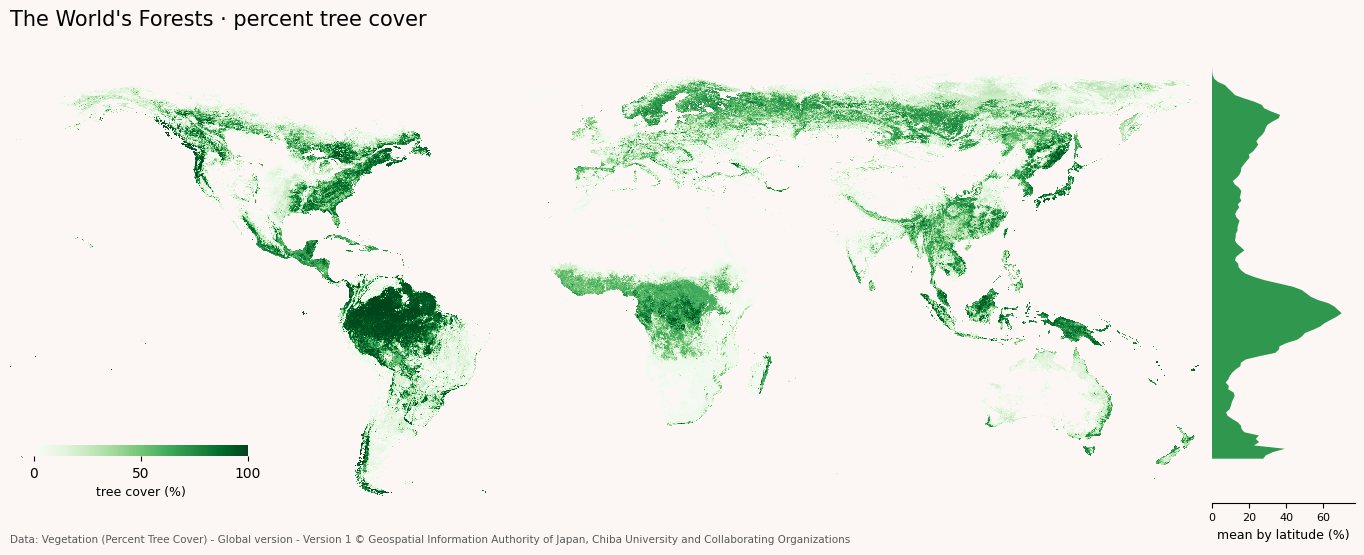

In [8]:
BG = "#FCF6F5"
colors = mpl.colormaps["Greens"].resampled(101)(np.linspace(0, 1, 101))
colors[0] = mpl.colors.to_rgba(BG)
forest_cmap = mpl.colors.ListedColormap(colors)
forest_cmap.set_bad(BG)

fig, ax = plt.subplots(figsize=(14, 5.6), facecolor=BG)
fig.subplots_adjust(left=0.01, right=0.86, top=0.92, bottom=0.08)

im = ax.imshow(coarse, cmap=forest_cmap, vmin=0, vmax=100, extent=(-180, 180, -90, 90), interpolation="nearest")
ax.set_ylim(-58, 84)
ax.set_axis_off()
ax.set_title("The World's Forests · percent tree cover", fontsize=15, loc="left")

cax = ax.inset_axes([0.02, 0.10, 0.18, 0.025])
cb = fig.colorbar(im, cax=cax, orientation="horizontal", ticks=[0, 50, 100])
cb.set_label("tree cover (%)", fontsize=9)
cb.outline.set_visible(False)

# The profile hangs off the map's own box, so latitudes line up exactly
axp = ax.inset_axes([1.01, 0, 0.12, 1], sharey=ax)
axp.fill_betweenx(band_lat, 0, band_mean, color=mpl.colormaps["Greens"](0.7), lw=0)
axp.set_facecolor(BG)
axp.set_xlim(0, np.nanmax(band_mean) * 1.1)
axp.set_xlabel("mean by latitude (%)", fontsize=9)
axp.tick_params(labelleft=False, left=False, labelsize=8)
for side in ("top", "right", "left"):
    axp.spines[side].set_visible(False)

fig.text(
    0.01, 0.01,
    "Data: Vegetation (Percent Tree Cover) - Global version - Version 1 © Geospatial Information Authority of Japan, "
    "Chiba University and Collaborating Organizations",
    fontsize=7.5, color="0.35",
)
fig.savefig(IMG_DIR / "world_forests.png", dpi=150, bbox_inches="tight", facecolor=BG)
plt.show()

## What changed from the 2023 version

- `cm.get_cmap` was removed in matplotlib 3.9 → `matplotlib.colormaps[...].resampled()`.
- The 87 MB GeoTIFF is no longer committed: `pooch` downloads the zip once, checks its hash and GDAL reads it in place.
- Statistics are **area-weighted**; pixel counts on a lat/lon grid would overweight high latitudes.
- The data source and its required copyright notice are cited on the figure.